# Практичне заняття № 5 — Метод K-найближчих сусідів

**Завдання.** Реалізувати алгоритм K-найближчих сусідів на одному з датасетів
[Kaggle: security](https://www.kaggle.com/datasets?search=security), визначити
його переваги та недоліки, дослідити залежність точності алгоритму від
особливостей використаного датасету.

**Датасет: UGRansome** — той самий, що в практичних заняттях № 2 і № 3, і та сама
підвибірка 30 000 записів з тим самим зерном, що в занятті № 3. Це дає прямо
порівнянні числа для дерева, лісу, SVM, логістичної регресії та kNN.

## Теорія

kNN не має етапу навчання в звичайному розумінні: він просто запам'ятовує
навчальну вибірку. Щоб класифікувати новий об'єкт, метод знаходить $k$
найближчих до нього прикладів і повертає клас, за який «проголосувала»
більшість. Через це його називають **лінивим** (lazy learning) або
**методом на основі прикладів**.

Наслідок такої будови: обчислення переносяться з навчання на передбачення. Це
принципово відрізняє kNN від усіх попередніх методів і визначає більшість його
переваг та недоліків.

**Досліджувані особливості даних:** масштаб ознак, розмірність простору,
щільність вибірки, наявність нерелевантних ознак.

In [1]:
# --- Підготовка даних -------------------------------------------------------
# Ноутбук має запускатися і локально, і в Colab. Якщо потрібного файлу немає,
# він завантажується з Kaggle. Форму таблиці перевіряємо одразу: Kaggle може
# оновити версію набору, і краще впасти тут, ніж мовчки отримати інші числа,
# ніж у звіті.
import importlib.util
import shutil
import subprocess
import sys
from pathlib import Path


def _in_colab():
    if "google.colab" in sys.modules:
        return True
    try:
        return importlib.util.find_spec("google.colab") is not None
    except (ImportError, ValueError):
        # find_spec імпортує батьківський пакет; без нього — це не Colab
        return False


IN_COLAB = _in_colab()
DATA = Path("data"); DATA.mkdir(exist_ok=True)
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)

# (локальна назва, slug на Kaggle, файл у наборі, колонок, рядків, кодування)
DATASETS = [
    ('ugransome.csv', 'nkongolo/ugransome-dataset',
     'final(2).csv', 14, 149043, 'utf-8')
]


def _ensure_packages():
    """У Colab більшість пакетів уже є; доставляємо лише те, чого бракує."""
    missing = [p for p in ("pandas", "sklearn", "matplotlib", "seaborn", "kagglehub")
               if importlib.util.find_spec(p) is None]
    if missing:
        names = {"sklearn": "scikit-learn"}
        pkgs = [names.get(m, m) for m in missing]
        print("встановлюю:", ", ".join(pkgs))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)


def _check(path, ncols, nrows, encoding):
    # Перевіряємо і колонки, і рядки: нова версія набору може зберегти структуру,
    # але змінити обсяг — і числа у звіті тихо перестануть збігатися.
    import pandas as pd
    got = pd.read_csv(path, encoding=encoding).shape
    if got != (nrows, ncols):
        raise ValueError(f"{path.name}: очікували {nrows}×{ncols}, отримали {got[0]}×{got[1]}")


def _ensure(local, slug, member, ncols, nrows, encoding):
    dst = DATA / local
    if dst.exists():
        _check(dst, ncols, nrows, encoding)
        print(f"на місці: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    if importlib.util.find_spec("kagglehub"):
        import kagglehub
        print(f"завантажую {slug} …")
        root = Path(kagglehub.dataset_download(slug))
        src = next(iter(root.rglob(member)), None)
        if src is None:   # назву файлу в наборі могли змінити — беремо найбільший CSV
            src = max(root.rglob("*.csv"), key=lambda f: f.stat().st_size)
        shutil.copy(src, dst)
        _check(dst, ncols, nrows, encoding)
        print(f"готово: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    raise FileNotFoundError(
        f"{dst} не знайдено. Візьміть набір за адресою "
        f"https://www.kaggle.com/datasets/{slug} і покладіть файл у {DATA}/ "
        f"під назвою {local}."
    )


if IN_COLAB:
    _ensure_packages()
for _args in DATASETS:
    _ensure(*_args)

на місці: data/ugransome.csv (10.0 МБ)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from pathlib import Path

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

RANDOM_STATE = 42
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
np.random.seed(RANDOM_STATE)

N_MAIN = 30000   # та сама підвибірка, що й у практичному занятті № 3

## 1. Дані

In [3]:
df = pd.read_csv("data/ugransome.csv")
y_all = df["Prediction"].copy()
X_all = df.drop(columns=["Prediction"]).copy()
for col in X_all.select_dtypes(include=["object", "string"]).columns:
    X_all[col] = X_all[col].astype("category").cat.codes

X, _, y, _ = train_test_split(X_all, y_all, train_size=N_MAIN,
                              random_state=RANDOM_STATE, stratify=y_all)
X = X.reset_index(drop=True); y = y.reset_index(drop=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
cv = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

print(f"Підвибірка: {len(X)} записів, {X.shape[1]} ознак")
print(f"Класи: {dict(y.value_counts())}")
print(f"Базова лінія: {y.value_counts(normalize=True).max():.4f}")

Підвибірка: 30000 записів, 13 ознак
Класи: {'S': np.int64(13361), 'A': np.int64(8567), 'SS': np.int64(8072)}
Базова лінія: 0.4454


## 2. Особливість даних № 1: масштаб ознак

kNN, як і SVM, ухвалює рішення на основі **відстаней**. Ознака з великим
діапазоном визначає евклідову відстань майже одноосібно, і решта ознак на
результат не впливає. Дерева до масштабу байдужі — тут різниця принципова.

У практичному занятті № 3 виміряно, що розмахи ознак UGRansome відрізняються у
63 189 разів (`USD` має розмах 126 378, `Flag` — лише 8). Перевіримо наслідки.

In [4]:
scaling_rows = []
for name, model in [
    ("Без масштабування", KNeighborsClassifier(n_neighbors=5)),
    ("StandardScaler", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))),
    ("MinMaxScaler", make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=5))),
]:
    s = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    scaling_rows.append({"Підготовка": name, "Точність": s.mean(), "Ст. відх.": s.std()})

scaling_df = pd.DataFrame(scaling_rows).set_index("Підготовка")
print(scaling_df.round(4).to_string())
print(f"\nВиграш від масштабування: "
      f"{scaling_df.loc['StandardScaler','Точність'] - scaling_df.loc['Без масштабування','Точність']:+.4f}")

                   Точність  Ст. відх.
Підготовка                            
Без масштабування    0.9710     0.0014
StandardScaler       0.9629     0.0005
MinMaxScaler         0.9628     0.0005

Виграш від масштабування: -0.0081


### Несподіванка: тут масштабування шкодить

Результат протилежний до очікуваного і до того, що спостерігалось для SVM
(практичне заняття № 3, +32 пункти від масштабування). Перевіримо, чи це стійкий
ефект, і з'ясуємо причину.

In [5]:
# Перевіряємо на кількох значеннях k, а не лише на k=5
print("Масштабування за різних k:")
for k in [1, 5, 15, 30]:
    a = cross_val_score(KNeighborsClassifier(n_neighbors=k), X, y, cv=cv).mean()
    b = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
                        X, y, cv=cv).mean()
    print(f"  k={k:2}: без={a:.4f}  StandardScaler={b:.4f}  різниця={b-a:+.4f}")

Масштабування за різних k:


  k= 1: без=0.9660  StandardScaler=0.9703  різниця=+0.0044


  k= 5: без=0.9710  StandardScaler=0.9629  різниця=-0.0081


  k=15: без=0.9641  StandardScaler=0.9497  різниця=-0.0144


  k=30: без=0.9508  StandardScaler=0.9368  різниця=-0.0140


In [6]:
# Причина: чи збігається інформативність ознаки з її розмахом?
rf_imp = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE,
                                n_jobs=-1).fit(X, y)
imp = pd.Series(rf_imp.feature_importances_, index=X.columns).sort_values(ascending=False)
rng_ = (X.max() - X.min())
comp = pd.DataFrame({"Важливість": imp, "Розмах": rng_[imp.index]}).head(7)
print(comp.round(4).to_string())
print()
print("USD — водночас НАЙВАЖЛИВІША ознака і НАЙШИРША за розмахом.")
print("Без масштабування евклідова відстань визначається майже виключно нею,")
print("тобто дані випадково отримують саме те зважування, яке потрібне.")
print("StandardScaler зрівнює USD з малоінформативними категоріальними кодами")
print("і тим розмиває сигнал. Що більше k, то сильніше шкодить це розмиття.")

               Важливість  Розмах
USD                0.2407  126378
BTC                0.1401    1979
Flag               0.1300       8
ExpAddress         0.1052       6
Clusters           0.0900      11
Port               0.0611       7
Netflow_Bytes      0.0599   12351

USD — водночас НАЙВАЖЛИВІША ознака і НАЙШИРША за розмахом.
Без масштабування евклідова відстань визначається майже виключно нею,
тобто дані випадково отримують саме те зважування, яке потрібне.
StandardScaler зрівнює USD з малоінформативними категоріальними кодами
і тим розмиває сигнал. Що більше k, то сильніше шкодить це розмиття.


## 3. Головний параметр: кількість сусідів k

`k = 1` означає, що клас визначає єдиний найближчий приклад — модель ідеально
відтворює навчальну вибірку (точність на ній 100 %), але вкрай чутлива до шуму.
Велике `k` усереднює по широкому околу, межа згладжується, і модель
недонавчається. Класичний компроміс зсуву та дисперсії.

In [7]:
k_values = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100]
scaler = StandardScaler().fit(X_train)
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)

k_rows = []
for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k).fit(Xtr_s, y_train)
    train_acc = m.score(Xtr_s, y_train)
    cv_acc = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
                             X, y, cv=cv, scoring="accuracy").mean()
    k_rows.append({"k": k, "Навчальна": train_acc, "Валідація": cv_acc,
                   "Розрив": train_acc - cv_acc})

k_df = pd.DataFrame(k_rows)
best_k = int(k_df.loc[k_df["Валідація"].idxmax(), "k"])
print(f"Найкраще k = {best_k} (точність {k_df['Валідація'].max():.4f})")
k_df.round(4)

Найкраще k = 1 (точність 0.9703)


,k,Навчальна,Валідація,Розрив
0,1,0.9996,0.9703,0.0293
1,2,0.9857,0.9626,0.0231
2,3,0.9847,0.9662,0.0185
3,5,0.9781,0.9629,0.0153
4,7,0.9742,0.9604,0.0138
5,10,0.9688,0.9559,0.0129
6,15,0.9628,0.9497,0.0131
7,20,0.9569,0.9458,0.0111
8,30,0.9464,0.9368,0.0096
9,50,0.9326,0.9235,0.0091


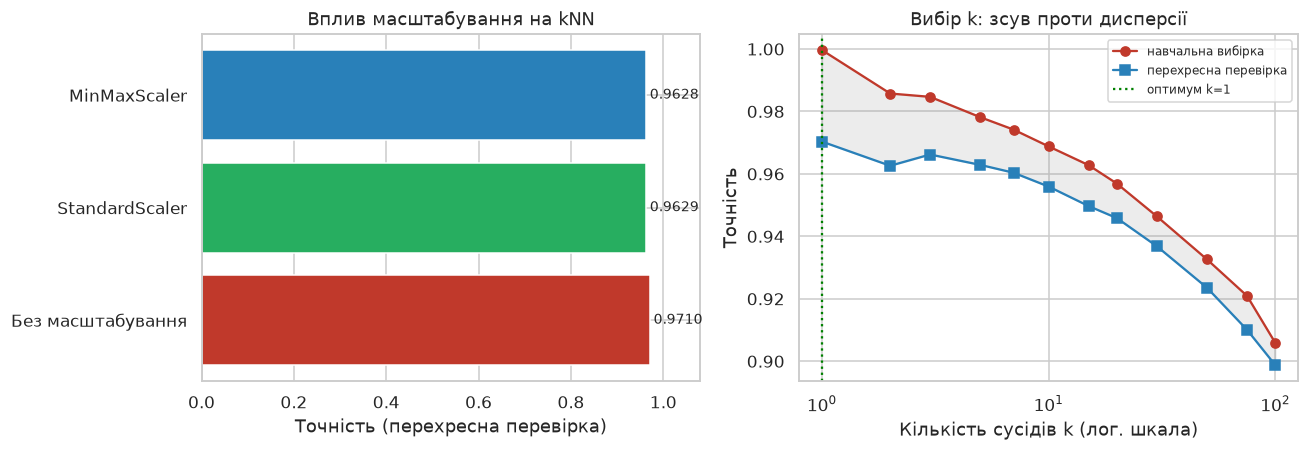

In [8]:
# --- Рисунок 1: масштабування та вибір k ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].barh(scaling_df.index, scaling_df["Точність"], color=["#c0392b", "#27ae60", "#2980b9"])
axes[0].set_xlabel("Точність (перехресна перевірка)")
axes[0].set_title("Вплив масштабування на kNN")
axes[0].set_xlim(0, 1.08)
for i, v in enumerate(scaling_df["Точність"]):
    axes[0].text(v + 0.008, i, f"{v:.4f}", va="center", fontsize=9)

axes[1].plot(k_df["k"], k_df["Навчальна"], "o-", label="навчальна вибірка", color="#c0392b")
axes[1].plot(k_df["k"], k_df["Валідація"], "s-", label="перехресна перевірка", color="#2980b9")
axes[1].fill_between(k_df["k"], k_df["Валідація"], k_df["Навчальна"], alpha=0.15, color="gray")
axes[1].axvline(best_k, color="green", linestyle=":", label=f"оптимум k={best_k}")
axes[1].set_xscale("log"); axes[1].set_xlabel("Кількість сусідів k (лог. шкала)")
axes[1].set_ylabel("Точність"); axes[1].set_title("Вибір k: зсув проти дисперсії")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "01-scaling-k.png", bbox_inches="tight")
plt.show()

## 4. Метрика відстані та вагування сусідів

- **Евклідова** ($p=2$) — звичайна геометрична відстань.
- **Манхеттенська** ($p=1$) — сума модулів різниць; у високій розмірності часто
  поводиться стабільніше.
- **Чебишевська** ($p=\infty$) — максимум різниці за однією з координат.

`weights="distance"` зважує голоси сусідів обернено до відстані: ближчі важать
більше.

In [9]:
metric_rows = []
for metric, p in [("Евклідова (p=2)", 2), ("Манхеттенська (p=1)", 1), ("Чебишевська (p=inf)", np.inf)]:
    for w in ["uniform", "distance"]:
        m = make_pipeline(StandardScaler(),
                          KNeighborsClassifier(n_neighbors=best_k, p=p, weights=w,
                                               metric="minkowski" if np.isfinite(p) else "chebyshev"))
        s = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
        metric_rows.append({"Метрика": metric,
                            "Вагування": "рівне" if w == "uniform" else "за відстанню",
                            "Точність": s.mean()})

metric_df = pd.DataFrame(metric_rows)
metric_df.pivot(index="Метрика", columns="Вагування", values="Точність").round(4)

Вагування,за відстанню,рівне
Метрика,,
Евклідова (p=2),0.9703,0.9703
Манхеттенська (p=1),0.9743,0.9743
Чебишевська (p=inf),0.9644,0.9644


In [10]:
# Структура пошуку: чи окупаються просторові індекси на 13 вимірах?
# (звіт посилається на ці числа, тож замір має бути відтворюваним)
algo_rows = []
for algo in ["brute", "kd_tree", "ball_tree"]:
    m = KNeighborsClassifier(n_neighbors=best_k, algorithm=algo)
    t0 = time.time(); m.fit(Xtr_s, y_train); fit_t = time.time() - t0
    t0 = time.time(); acc = m.score(Xte_s, y_test); pred_t = time.time() - t0
    algo_rows.append({"Структура": algo, "Навчання, с": fit_t,
                      "Передбачення, с": pred_t, "Точність": acc})

algo_df = pd.DataFrame(algo_rows).set_index("Структура")
algo_df.to_csv("data/algorithms.csv")
print(algo_df.round(4).to_string())
print()
best_algo = algo_df["Передбачення, с"].idxmin()
print(f"На {Xtr_s.shape[1]} вимірах найшвидша структура — {best_algo}.")
print("Точність практично збігається; різниця лише у швидкості пошуку.")

           Навчання, с  Передбачення, с  Точність
Структура                                        
brute           0.0377           0.2461    0.9731
kd_tree         0.0569           0.1580    0.9727
ball_tree       0.0435           1.3409    0.9727

На 13 вимірах найшвидша структура — kd_tree.
Точність практично збігається; різниця лише у швидкості пошуку.


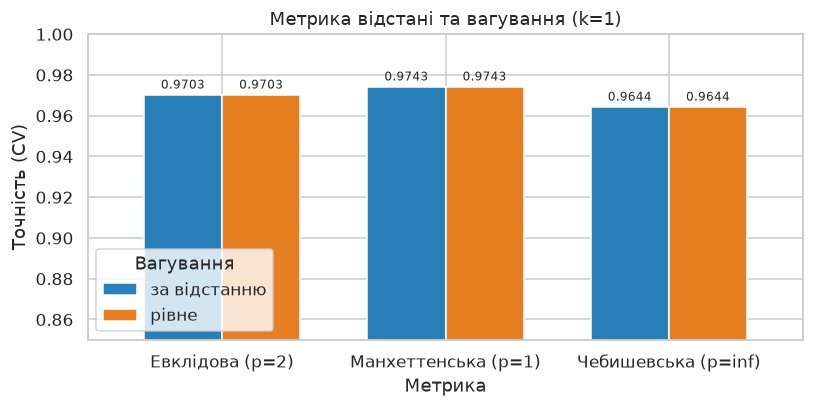

In [11]:
# --- Рисунок 2: метрики та вагування ---
fig, ax = plt.subplots(figsize=(7.5, 3.8))
piv = metric_df.pivot(index="Метрика", columns="Вагування", values="Точність")
piv.plot.bar(ax=ax, color=["#2980b9", "#e67e22"], width=0.7, rot=0)
ax.set_ylabel("Точність (CV)"); ax.set_title(f"Метрика відстані та вагування (k={best_k})")
ax.set_ylim(0.85, 1.0)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.4f", fontsize=8, padding=2)
plt.tight_layout()
plt.savefig(ASSETS / "02-metrics.png", bbox_inches="tight")
plt.show()

## 5. Особливість даних № 2: прокляття розмірності

Це головна слабкість kNN. У просторі високої розмірності відстані між точками
**концентруються**: різниця між найближчим і найдальшим сусідом стає відносно
малою, і поняття «близькості» втрачає сенс. Метод, побудований саме на близькості,
деградує.

Перевіримо це прямо: додамо до даних випадкові ознаки, які не несуть жодної
інформації, і подивимось, як зміниться точність kNN — і, для порівняння,
випадкового лісу, який здатен нерелевантні ознаки просто ігнорувати.

In [12]:
rng = np.random.RandomState(RANDOM_STATE)
noise_dims = [0, 5, 10, 20, 50, 100, 200]

# менша підвибірка, щоб експеримент рахувався швидко
idx = rng.choice(len(X), 10000, replace=False)
Xn_base, yn = X.iloc[idx].reset_index(drop=True), y.iloc[idx].reset_index(drop=True)

dim_rows = []
for d in noise_dims:
    if d == 0:
        Xn = Xn_base.copy()
    else:
        noise = pd.DataFrame(rng.randn(len(Xn_base), d),
                             columns=[f"noise_{i}" for i in range(d)])
        Xn = pd.concat([Xn_base, noise], axis=1)

    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
    rf = RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1)
    a_knn = cross_val_score(knn, Xn, yn, cv=3, scoring="accuracy").mean()
    a_rf = cross_val_score(rf, Xn, yn, cv=3, scoring="accuracy").mean()

    # діагностика концентрації відстаней
    Xs_ = StandardScaler().fit_transform(Xn)[:1500]
    from scipy.spatial.distance import pdist
    dists = pdist(Xs_)
    concentration = dists.min() / dists.max()

    dim_rows.append({"Шумових ознак": d, "Всього ознак": Xn.shape[1],
                     "kNN": a_knn, "Випадковий ліс": a_rf,
                     "Втрата kNN": a_knn - dim_rows[0]["kNN"] if dim_rows else 0.0,
                     "min/max відстані": concentration})

dim_df = pd.DataFrame(dim_rows)
dim_df["Втрата kNN"] = dim_df["kNN"] - dim_df["kNN"].iloc[0]
dim_df["Втрата лісу"] = dim_df["Випадковий ліс"] - dim_df["Випадковий ліс"].iloc[0]
dim_df.to_csv("data/dimensionality.csv", index=False)
dim_df.round(4)

,Шумових ознак,Всього ознак,kNN,Випадковий ліс,Втрата kNN,min/max відстані,Втрата лісу
0,0,13,0.9492,0.9828,0.0000,0.0001,0.0000
1,5,18,0.8720,0.9742,-0.0772,0.0515,-0.0086
2,10,23,0.8258,0.9682,-0.1234,0.0812,-0.0146
3,20,33,0.7368,0.9655,-0.2124,0.1653,-0.0173
4,50,63,0.6102,0.9567,-0.3390,0.2969,-0.0261
5,100,113,0.5191,0.9465,-0.4301,0.4028,-0.0363
6,200,213,0.4659,0.9343,-0.4833,0.5447,-0.0485


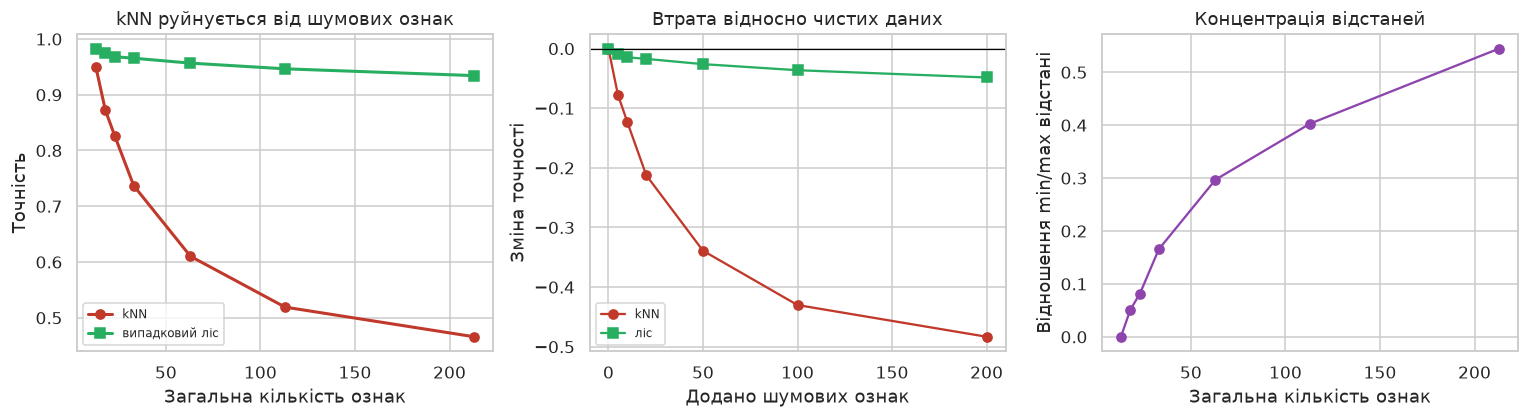

При 200 шумових ознаках: kNN -0.4833, ліс -0.0485


In [13]:
# --- Рисунок 3: прокляття розмірності ---
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))

axes[0].plot(dim_df["Всього ознак"], dim_df["kNN"], "o-", label="kNN", color="#c0392b", linewidth=2)
axes[0].plot(dim_df["Всього ознак"], dim_df["Випадковий ліс"], "s-", label="випадковий ліс",
             color="#27ae60", linewidth=2)
axes[0].set_xlabel("Загальна кількість ознак"); axes[0].set_ylabel("Точність")
axes[0].set_title("kNN руйнується від шумових ознак"); axes[0].legend(fontsize=8)

axes[1].plot(dim_df["Шумових ознак"], dim_df["Втрата kNN"], "o-", color="#c0392b", label="kNN")
axes[1].plot(dim_df["Шумових ознак"], dim_df["Втрата лісу"], "s-", color="#27ae60", label="ліс")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Додано шумових ознак"); axes[1].set_ylabel("Зміна точності")
axes[1].set_title("Втрата відносно чистих даних"); axes[1].legend(fontsize=8)

axes[2].plot(dim_df["Всього ознак"], dim_df["min/max відстані"], "o-", color="#8e44ad")
axes[2].set_xlabel("Загальна кількість ознак")
axes[2].set_ylabel("Відношення min/max відстані")
axes[2].set_title("Концентрація відстаней")

plt.tight_layout()
plt.savefig(ASSETS / "03-dimensionality.png", bbox_inches="tight")
plt.show()

print(f"При 200 шумових ознаках: kNN {dim_df['Втрата kNN'].iloc[-1]:+.4f}, "
      f"ліс {dim_df['Втрата лісу'].iloc[-1]:+.4f}")

## 6. Особливість даних № 3: щільність вибірки та вартість передбачення

kNN — лінива модель: навчання зводиться до запам'ятовування, а вся робота
відбувається під час передбачення. Це дає унікальну властивість: **час
передбачення зростає з розміром навчальної вибірки**, чого не буває в
«жадібних» моделей.

In [14]:
sizes = [1000, 2500, 5000, 10000, 20000, 40000, 80000]
time_rows = []
for n in sizes:
    Xs_, _, ys_, _ = train_test_split(X_all, y_all, train_size=n,
                                      random_state=RANDOM_STATE, stratify=y_all)
    Xtr_, Xte_, ytr_, yte_ = train_test_split(Xs_, ys_, test_size=0.25,
                                              random_state=RANDOM_STATE, stratify=ys_)
    sc = StandardScaler().fit(Xtr_)
    A, B = sc.transform(Xtr_), sc.transform(Xte_)
    m = KNeighborsClassifier(n_neighbors=best_k)
    t0 = time.time(); m.fit(A, ytr_); fit_t = time.time() - t0
    t0 = time.time(); acc = m.score(B, yte_); pred_t = time.time() - t0
    time_rows.append({"Розмір": n, "Точність": acc,
                      "Навчання, мс": fit_t * 1000,
                      "Передбачення, мс": pred_t * 1000,
                      "мс на 1 запит": pred_t * 1000 / len(B)})

time_df = pd.DataFrame(time_rows)
time_df.to_csv("data/timing.csv", index=False)
time_df.round(4)

,Розмір,Точність,"Навчання, мс","Передбачення, мс",мс на 1 запит
0,1000,0.9080,1.5903,5.5528,0.0222
1,2500,0.9232,3.2067,9.8989,0.0158
2,5000,0.9440,9.1126,24.5364,0.0196
3,10000,0.9488,14.5681,52.3303,0.0209
4,20000,0.9656,30.0202,104.7077,0.0209
5,40000,0.9771,80.2240,210.9196,0.0211
6,80000,0.9810,151.4537,485.1694,0.0243


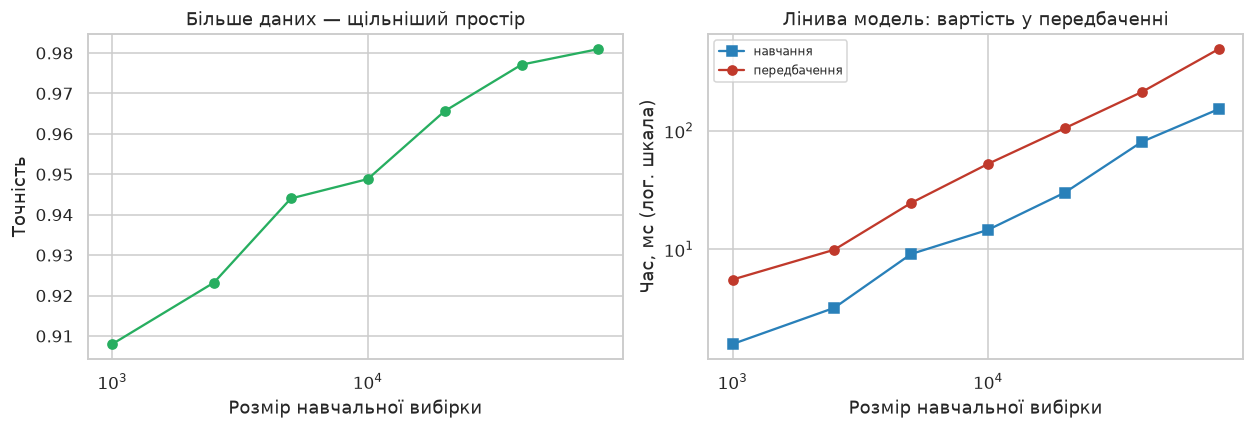

На 80 000 прикладів передбачення повільніше за навчання у 3 разів


In [15]:
# --- Рисунок 4: лінива модель ---
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
axes[0].plot(time_df["Розмір"], time_df["Точність"], "o-", color="#27ae60")
axes[0].set_xscale("log"); axes[0].set_xlabel("Розмір навчальної вибірки")
axes[0].set_ylabel("Точність"); axes[0].set_title("Більше даних — щільніший простір")

axes[1].plot(time_df["Розмір"], time_df["Навчання, мс"], "s-", label="навчання", color="#2980b9")
axes[1].plot(time_df["Розмір"], time_df["Передбачення, мс"], "o-", label="передбачення", color="#c0392b")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Розмір навчальної вибірки"); axes[1].set_ylabel("Час, мс (лог. шкала)")
axes[1].set_title("Лінива модель: вартість у передбаченні"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "04-lazy.png", bbox_inches="tight")
plt.show()

r = time_df["Передбачення, мс"].iloc[-1] / time_df["Навчання, мс"].iloc[-1]
print(f"На 80 000 прикладів передбачення повільніше за навчання у {r:.0f} разів")

## 7. Підсумкова модель

              precision    recall  f1-score   support

           A     0.9538    0.9631    0.9584      2142
           S     0.9792    0.9737    0.9764      3340
          SS     0.9821    0.9812    0.9817      2018

    accuracy                         0.9727      7500
   macro avg     0.9717    0.9726    0.9722      7500
weighted avg     0.9727    0.9727    0.9727      7500



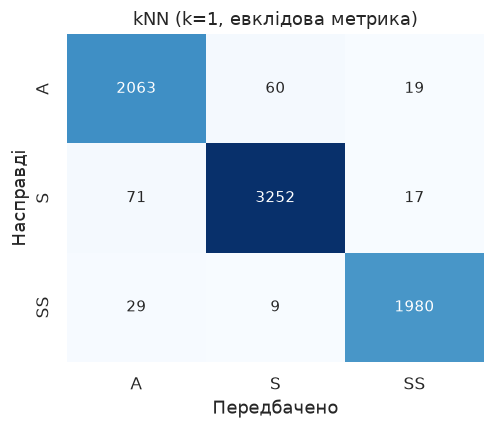

In [16]:
final_knn = make_pipeline(StandardScaler(),
                          KNeighborsClassifier(n_neighbors=best_k, weights="distance"))
final_knn.fit(X_train, y_train)
pred = final_knn.predict(X_test)
print(classification_report(y_test, pred, digits=4))

fig, ax = plt.subplots(figsize=(4.6, 4))
classes = sorted(y.unique())
cm = confusion_matrix(y_test, pred, labels=classes)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=classes, yticklabels=classes)
ax.set_xlabel("Передбачено"); ax.set_ylabel("Насправді")
ax.set_title(f"kNN (k={best_k}, евклідова метрика)")
plt.tight_layout()
plt.savefig(ASSETS / "05-confusion.png", bbox_inches="tight")
plt.show()

In [17]:
final_rows = []
for name, model in [
    (f"kNN (k={best_k}, манхеттенська)",
     make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k, p=1))),
    (f"kNN (k={best_k}, евклідова)", final_knn),
    ("Дерево рішень (ПЗ № 2)", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ("Випадковий ліс (ПЗ № 2)", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    ("SVM RBF (ПЗ № 3)", make_pipeline(StandardScaler(), SVC(kernel="rbf", C=100, gamma=0.1, random_state=RANDOM_STATE))),
    ("Логістична регресія", make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))),
]:
    s = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    final_rows.append({"Модель": name, "Точність (CV)": s.mean(),
                       "F1-macro": f1_score(y_test, p, average="macro")})

final = pd.DataFrame(final_rows).set_index("Модель").sort_values("Точність (CV)", ascending=False)
final.to_csv("data/results-summary.csv")
final.round(4)

,Точність (CV),F1-macro
Модель,,
Випадковий ліс (ПЗ № 2),0.9910,0.9914
Дерево рішень (ПЗ № 2),0.9907,0.9905
"kNN (k=1, манхеттенська)",0.9743,0.9757
SVM RBF (ПЗ № 3),0.9727,0.9715
"kNN (k=1, евклідова)",0.9703,0.9722
Логістична регресія (ПЗ № 1),0.7480,0.7263


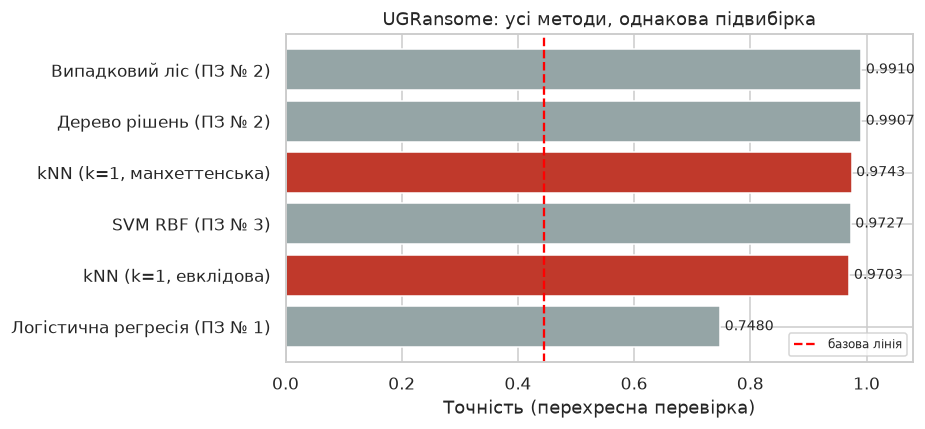

In [18]:
# --- Рисунок 5: підсумкове порівняння ---
fig, ax = plt.subplots(figsize=(8.5, 4))
colors = ["#c0392b" if "kNN" in i else "#95a5a6" for i in final.index]
bars = ax.barh(final.index[::-1], final["Точність (CV)"][::-1], color=colors[::-1])
ax.axvline(y.value_counts(normalize=True).max(), color="red", linestyle="--", label="базова лінія")
ax.set_xlabel("Точність (перехресна перевірка)"); ax.set_xlim(0, 1.08)
ax.set_title("UGRansome: усі методи, однакова підвибірка")
ax.legend(fontsize=8, loc="lower right")
for b, v in zip(bars, final["Точність (CV)"][::-1]):
    ax.text(v + 0.008, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(ASSETS / "06-final.png", bbox_inches="tight")
plt.show()

## 8. Підсумок

In [19]:
print("Масштабування:");        print(scaling_df.round(4).to_markdown()); print()
print("Вибір k:");              print(k_df.round(4).to_markdown(index=False)); print()
print("Прокляття розмірності:"); print(dim_df.round(4).to_markdown(index=False)); print()
print("Хронометраж:");          print(time_df.round(3).to_markdown(index=False)); print()
print("Порівняння методів:");   print(final.round(4).to_markdown())

Масштабування:
| Підготовка        |   Точність |   Ст. відх. |
|:------------------|-----------:|------------:|
| Без масштабування |     0.971  |      0.0014 |
| StandardScaler    |     0.9629 |      0.0005 |
| MinMaxScaler      |     0.9628 |      0.0005 |

Вибір k:
|   k |   Навчальна |   Валідація |   Розрив |
|----:|------------:|------------:|---------:|
|   1 |      0.9996 |      0.9703 |   0.0293 |
|   2 |      0.9857 |      0.9626 |   0.0231 |
|   3 |      0.9847 |      0.9662 |   0.0185 |
|   5 |      0.9781 |      0.9629 |   0.0153 |
|   7 |      0.9742 |      0.9604 |   0.0138 |
|  10 |      0.9688 |      0.9559 |   0.0129 |
|  15 |      0.9628 |      0.9497 |   0.0131 |
|  20 |      0.9569 |      0.9458 |   0.0111 |
|  30 |      0.9464 |      0.9368 |   0.0096 |
|  50 |      0.9326 |      0.9235 |   0.0091 |
|  75 |      0.9209 |      0.9101 |   0.0109 |
| 100 |      0.9059 |      0.8987 |   0.0071 |

Прокляття розмірності:
|   Шумових ознак |   Всього ознак |    kNN |   